# Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU

**Foundations of Generative AI (ICT4403) — Assignment 2**

**Student:** Nandan Reddy Maram (230911032)

This notebook builds and compares four recurrent architectures — **Simple RNN**, **Bidirectional RNN**, **LSTM** and **GRU** — for word-level autoregressive next-word prediction and text generation. All models are trained under comparable experimental conditions (same data splits, sequence length, embedding size, hidden units, optimizer, batch size and number of epochs) and evaluated both quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence, diversity, contextual consistency, repetition), including generation with multiple sampling temperatures.


## 1. Setup and configuration

In [1]:
%matplotlib inline
import os
import re
import json
import time
import math
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = os.path.join("data", "alice_in_wonderland.txt")
RESULTS_DIR = "results"
FIG_DIR = "figures"
GEN_DIR = "generated_text"
MODELS_DIR = "models"
for d in (RESULTS_DIR, FIG_DIR, GEN_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

SEQ_LEN = 15
EMBED_DIM = 64
RNN_UNITS = 128
BATCH_SIZE = 128
EPOCHS = 10
MAX_VOCAB = 5000
MIN_FREQ = 2
TEMPERATURES = [0.5, 1.0, 1.5]
N_GEN_WORDS = 100

print("TensorFlow:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))
print(f"Config: SEQ_LEN={SEQ_LEN}, EMBED_DIM={EMBED_DIM}, RNN_UNITS={RNN_UNITS}, "
      f"BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS}, MAX_VOCAB={MAX_VOCAB}")


TensorFlow: 2.19.0
GPUs available: []
Config: SEQ_LEN=15, EMBED_DIM=64, RNN_UNITS=128, BATCH_SIZE=128, EPOCHS=10, MAX_VOCAB=5000


## 2. Dataset selection, loading and characteristics

**Dataset:** *Alice's Adventures in Wonderland* by Lewis Carroll — Project Gutenberg eBook [#11](https://www.gutenberg.org/ebooks/11).

**Source (plain text):** https://www.gutenberg.org/cache/epub/11/pg11.txt

**Why this dataset?** It is a classic English narrative-fiction corpus of moderate size (~174 KB plain text) with rich, varied sentence structure, dialogue and recurring characters. It is large enough to train RNN language models that exhibit learnable syntax and topical consistency, yet small enough to train four architectures quickly on CPU under identical conditions. It is freely available with a stable public URL, making the experiment fully reproducible.

We strip the Project Gutenberg license header/footer before analysis.

In [2]:
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = f.read()

start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"
s, e = raw.find(start_marker), raw.find(end_marker)
text = raw[s + len(start_marker):e] if s != -1 and e != -1 else raw
text = text.strip()

print(f"Characters after cleaning: {len(text):,}")
print("\nFirst 500 characters:")
print(text[:500])


Characters after cleaning: 144,637

First 500 characters:
ALICE'S ADVENTURES IN WONDERLAND ***

[Illustration]




Alice’s Adventures in Wonderland

by Lewis Carroll

THE MILLENNIUM FULCRUM EDITION 3.0

Contents

 CHAPTER I.     Down the Rabbit-Hole
 CHAPTER II.    The Pool of Tears
 CHAPTER III.   A Caucus-Race and a Long Tale
 CHAPTER IV.    The Rabbit Sends in a Little Bill
 CHAPTER V.     Advice from a Caterpillar
 CHAPTER VI.    Pig and Pepper
 CHAPTER VII.   A Mad Tea-Party
 CHAPTER VIII.  The Queen’s Croquet-Ground
 CHAPTER IX.    The Mock Turtl


### 2.1 Exploratory statistics

We use a regex tokenizer that keeps alphabetic words (including contractions such as *alice's*) and the punctuation marks `.,!?;:` as separate tokens, so the model can learn sentence boundaries.

Total tokens (words + punctuation): 31,938
Word tokens: 27,431
Unique words: 2,576
Average word length: 3.94 characters
Type/token ratio: 0.0939


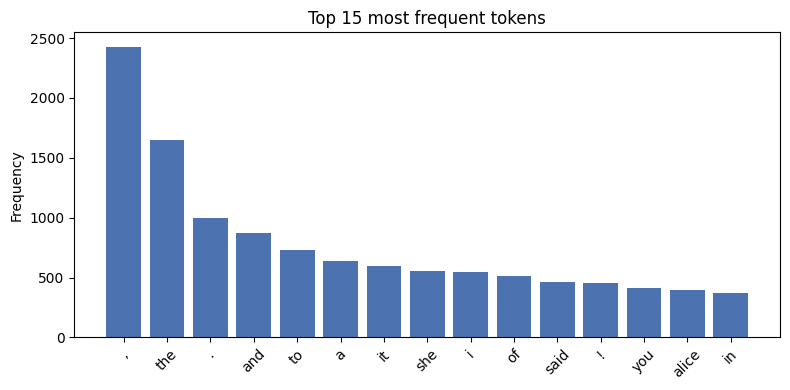

In [3]:
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[.,!?;:]")

def tokenize(text):
    return TOKEN_RE.findall(text.lower())

tokens = tokenize(text)
word_tokens = [t for t in tokens if t[0].isalpha()]
unique_words = set(word_tokens)

print(f"Total tokens (words + punctuation): {len(tokens):,}")
print(f"Word tokens: {len(word_tokens):,}")
print(f"Unique words: {len(unique_words):,}")
print(f"Average word length: {np.mean([len(w) for w in word_tokens]):.2f} characters")
print(f"Type/token ratio: {len(unique_words) / len(word_tokens):.4f}")

counts = Counter(tokens)
top = counts.most_common(15)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([w for w, _ in top], [c for _, c in top], color="#4C72B0")
ax.set_title("Top 15 most frequent tokens")
ax.set_ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "token_frequency.png"), dpi=150)
plt.show()


### 2.2 Train / validation / test split and vocabulary

We use a **chronological split** (first 80 % of tokens → train, next 10 % → validation, last 10 % → test). This avoids the leakage that a random split would cause on highly overlapping sliding windows and better reflects true next-word prediction.

The vocabulary is built from the **training portion only** (tokens appearing at least `MIN_FREQ` times, capped at `MAX_VOCAB`). Rare and unseen tokens map to `<oov>`; `<pad>` (index 0) is reserved for left-padding short seed contexts at generation time.

### 2.3 Input–target sequence construction

For autoregressive next-word modelling, every consecutive window of `SEQ_LEN = 15` tokens is an input and the following token is the target:

```
[x_t-14, ..., x_t-1, x_t]  ->  x_t+1
```

This many-to-one formulation is directly usable for generation: repeatedly predict the next word from the last 15 tokens of the (growing) output.


In [4]:
n = len(tokens)
i1, i2 = int(0.8 * n), int(0.9 * n)
train_tok, val_tok, test_tok = tokens[:i1], tokens[i1:i2], tokens[i2:]
print(f"Token split — train: {len(train_tok):,} | val: {len(val_tok):,} | test: {len(test_tok):,}")

counts_train = Counter(train_tok)
vocab = [w for w, c in counts_train.most_common() if c >= MIN_FREQ][: MAX_VOCAB - 2]
word_index = {"<pad>": 0, "<oov>": 1}
for w in vocab:
    word_index[w] = len(word_index)
index_word = {i: w for w, i in word_index.items()}
vocab_size = len(word_index)
print(f"Vocabulary size: {vocab_size:,}")

def make_xy(toks):
    ids = [word_index.get(t, word_index["<oov>"]) for t in toks]
    X, y = [], []
    for start in range(0, len(ids) - SEQ_LEN):
        X.append(ids[start:start + SEQ_LEN])
        y.append(ids[start + SEQ_LEN])
    return np.array(X, dtype=np.int32), np.array(y, dtype=np.int32)

X_train, y_train = make_xy(train_tok)
X_val, y_val = make_xy(val_tok)
X_test, y_test = make_xy(test_tok)
print(f"Sequences — train: {len(X_train):,} | val: {len(X_val):,} | test: {len(X_test):,}")
print(f"Input shape: {X_train.shape}, target shape: {y_train.shape}")
print(f"Example input : {' '.join(index_word[i] for i in X_train[0])}")
print(f"Example target: {index_word[y_train[0]]}")


Token split — train: 25,550 | val: 3,194 | test: 3,194
Vocabulary size: 1,282


Sequences — train: 25,535 | val: 3,179 | test: 3,179
Input shape: (25535, 15), target shape: (25535,)
Example input : <oov> adventures in wonderland <oov> alice s adventures in wonderland by <oov> <oov> the <oov>
Example target: <oov>


## 3. Models

All four models share the same stack: `Embedding(vocab, 64)` → recurrent layer (128 units) → `Dense(vocab, softmax)`, trained with Adam and sparse categorical cross-entropy. The only difference is the recurrent layer:

| Model | Recurrent layer |
|---|---|
| Simple RNN | `SimpleRNN(128)` |
| Bidirectional RNN | `Bidirectional(SimpleRNN(128))` |
| LSTM | `LSTM(128)` |
| GRU | `GRU(128)` |

The bidirectional model encodes each 15-token context window with forward and backward passes (both directions only ever see the context window, never the prediction target), then concatenates the two final states. At generation time it predicts the token **after** the window, so it remains a valid autoregressive next-word model — though, as discussed in the analysis, its backward pass is ill-suited to free-running generation.


In [5]:
def build_model(kind, vocab_size=vocab_size, seq_len=SEQ_LEN,
                embed_dim=EMBED_DIM, units=RNN_UNITS):
    inputs = keras.Input(shape=(seq_len,), name="context")
    x = layers.Embedding(vocab_size, embed_dim, name="embedding")(inputs)
    if kind == "simple_rnn":
        x = layers.SimpleRNN(units, name="rnn")(x)
    elif kind == "bidirectional_rnn":
        x = layers.Bidirectional(layers.SimpleRNN(units), name="birection")(x)
    elif kind == "lstm":
        x = layers.LSTM(units, name="lstm")(x)
    elif kind == "gru":
        x = layers.GRU(units, name="gru")(x)
    else:
        raise ValueError(f"Unknown model kind: {kind}")
    outputs = layers.Dense(vocab_size, activation="softmax", name="next_word")(x)
    model = keras.Model(inputs, outputs, name=kind)
    model.compile(optimizer=keras.optimizers.Adam(),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def perplexity(loss):
    return float(np.exp(np.clip(loss, 0.0, 20.0)))

MODEL_KINDS = ["simple_rnn", "bidirectional_rnn", "lstm", "gru"]
MODEL_LABELS = {
    "simple_rnn": "Simple RNN",
    "bidirectional_rnn": "Bidirectional RNN",
    "lstm": "LSTM",
    "gru": "GRU",
}

for kind in MODEL_KINDS:
    m = build_model(kind)
    print(f"{MODEL_LABELS[kind]:20s} | params: {m.count_params():,}")


Simple RNN           | params: 272,130
Bidirectional RNN    | params: 460,930
LSTM                 | params: 346,242


GRU                  | params: 321,922


## 4. Training (identical conditions for all models))

Each model is trained for the same 10 epochs with the same batch size and data splits. We record wall-clock training time per model.

In [6]:
histories, train_times, param_counts = {}, {}, {}

for kind in MODEL_KINDS:
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    model = build_model(kind)
    param_counts[kind] = model.count_params()
    t0 = time.time()
    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        verbose=2,
    )
    train_times[kind] = time.time() - t0
    histories[kind] = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    model.save(os.path.join(MODELS_DIR, f"{kind}.keras"))
    print(f">>> {MODEL_LABELS[kind]}: {train_times[kind]:.1f}s, params={param_counts[kind]:,}\n")

with open(os.path.join(RESULTS_DIR, "histories.json"), "w") as f:
    json.dump(histories, f, indent=2)


Epoch 1/10


200/200 - 8s - 38ms/step - accuracy: 0.0728 - loss: 5.6568 - val_accuracy: 0.0758 - val_loss: 5.1602


Epoch 2/10


200/200 - 5s - 23ms/step - accuracy: 0.1041 - loss: 5.2882 - val_accuracy: 0.1513 - val_loss: 5.0114


Epoch 3/10


...

Epoch 9/10


200/200 - 9s - 45ms/step - accuracy: 0.2254 - loss: 3.8316 - val_accuracy: 0.1941 - val_loss: 4.1411


Epoch 10/10


200/200 - 10s - 51ms/step - accuracy: 0.2368 - loss: 3.7193 - val_accuracy: 0.1953 - val_loss: 4.1280


>>> GRU: 99.3s, params=321,922



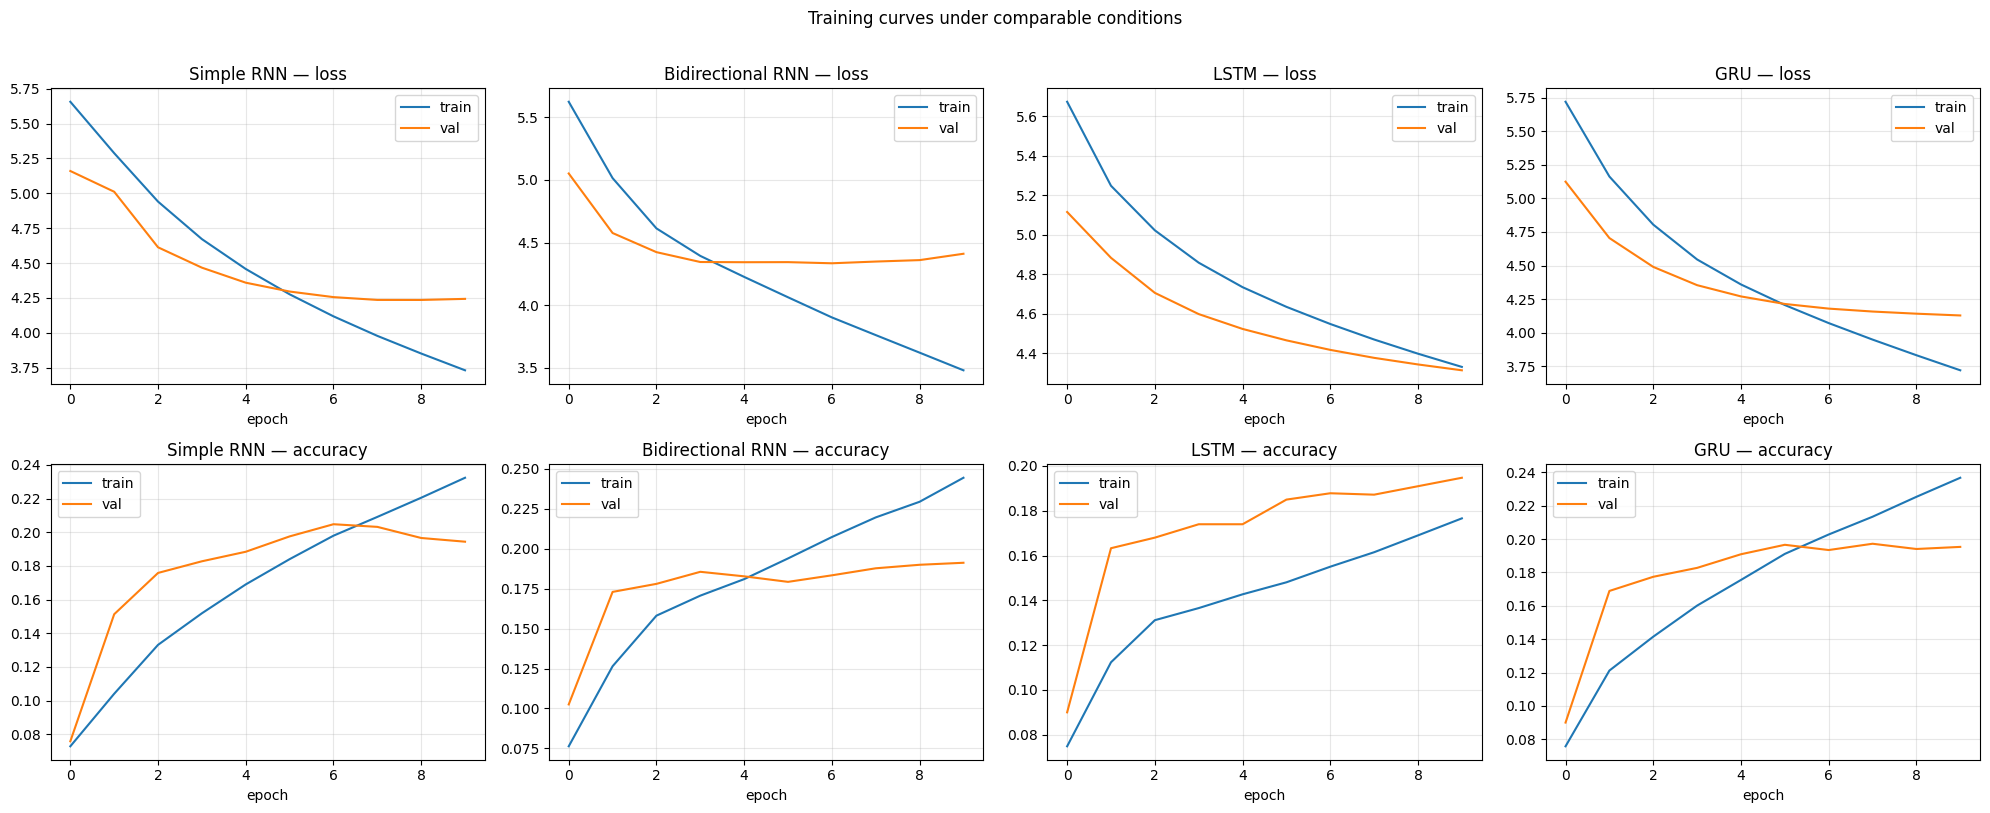

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, kind in enumerate(MODEL_KINDS):
    h = histories[kind]
    axes[0, j].plot(h["loss"], label="train")
    axes[0, j].plot(h["val_loss"], label="val")
    axes[0, j].set_title(f"{MODEL_LABELS[kind]} — loss")
    axes[0, j].set_xlabel("epoch")
    axes[0, j].legend()
    axes[0, j].grid(True, alpha=0.3)
    axes[1, j].plot(h["accuracy"], label="train")
    axes[1, j].plot(h["val_accuracy"], label="val")
    axes[1, j].set_title(f"{MODEL_LABELS[kind]} — accuracy")
    axes[1, j].set_xlabel("epoch")
    axes[1, j].legend()
    axes[1, j].grid(True, alpha=0.3)
plt.suptitle("Training curves under comparable conditions", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()


## 5. Quantitative evaluation

**Metrics** on the held-out test set:

- **Test loss** — average sparse categorical cross-entropy of next-word predictions.
- **Perplexity** — `exp(test_loss)`, the standard language-model measure (lower is better); it can be read as the effective branching factor of predicted next words.
- **Prediction accuracy** — fraction of test windows where the argmax next-word prediction is correct.
- **Training time** — wall-clock seconds for the fixed 10-epoch budget.


In [8]:
rows = []
for kind in MODEL_KINDS:
    model = keras.models.load_model(os.path.join(MODELS_DIR, f"{kind}.keras"))
    test_loss, test_acc = model.evaluate(X_test, y_test, batch_size=BATCH_SIZE, verbose=0)
    rows.append({
        "model": MODEL_LABELS[kind],
        "parameters": param_counts[kind],
        "train_time_s": round(train_times[kind], 1),
        "final_train_loss": round(histories[kind]["loss"][-1], 4),
        "final_val_loss": round(histories[kind]["val_loss"][-1], 4),
        "test_loss": round(float(test_loss), 4),
        "test_perplexity": round(perplexity(test_loss), 2),
        "test_accuracy": round(float(test_acc), 4),
    })

df_metrics = pd.DataFrame(rows)
df_metrics.to_csv(os.path.join(RESULTS_DIR, "model_metrics.csv"), index=False)
df_metrics


,model,parameters,train_time_s,final_train_loss,final_val_loss,test_loss,test_perplexity,test_accuracy
0,Simple RNN,272130,43.5,3.7309,4.2431,4.3005,73.74,0.2042
1,Bidirectional RNN,460930,57.1,3.4815,4.4108,4.4565,86.18,0.1897
2,LSTM,346242,104.0,4.3297,4.3126,4.3468,77.23,0.2095
3,GRU,321922,99.3,3.7193,4.1280,4.1853,65.71,0.2098


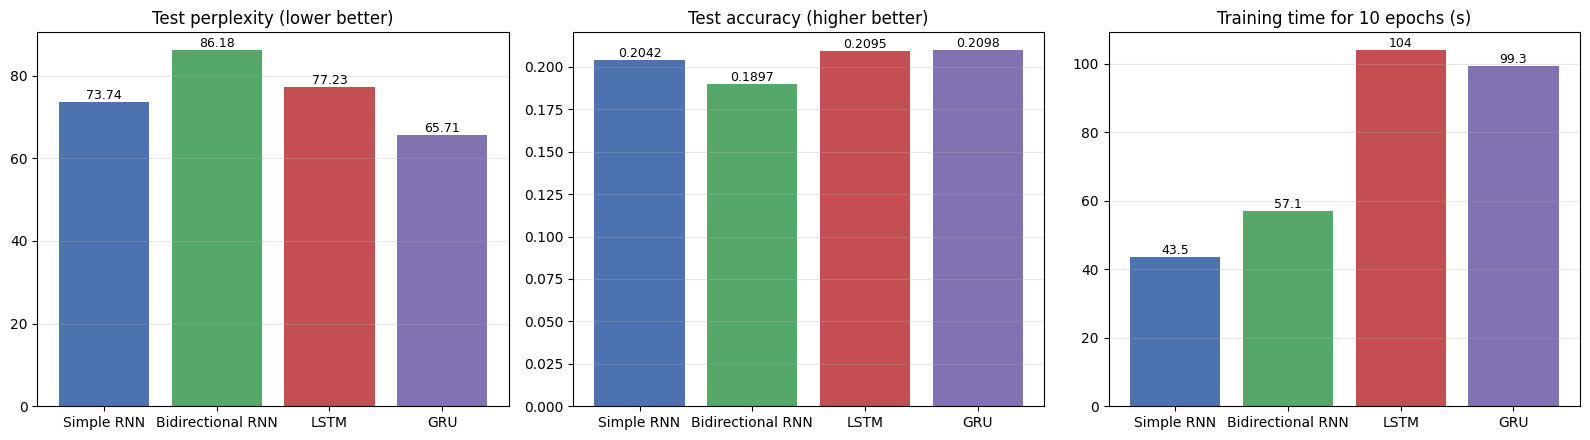

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]
panels = [
    ("test_perplexity", "Test perplexity (lower better)"),
    ("test_accuracy", "Test accuracy (higher better)"),
    ("train_time_s", "Training time for 10 epochs (s)"),
]
for ax, (col, title) in zip(axes, panels):
    bars = ax.bar(df_metrics["model"], df_metrics[col], color=colors)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    for rect, v in zip(bars, df_metrics[col]):
        ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:g}",
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "model_comparison.png"), dpi=150)
plt.show()


## 6. Text generation from seed sequences

We generate 100 words from each of two seed sentences taken from the book, for every model, at three sampling temperatures: **0.5** (conservative), **1.0** (default) and **1.5** (creative).

At each step the last `SEQ_LEN` tokens of the current output are fed to the model and the softmax distribution over the vocabulary is sampled with temperature scaling:

$$p_i(T) = \frac{\exp(\log p_i / T)}{\sum_j \exp(\log p_j / T)}$$


In [10]:
def sample_with_temperature(probs, temperature):
    if temperature <= 0:
        return int(np.argmax(probs))
    logp = np.log(np.clip(probs, 1e-12, 1.0)) / temperature
    exp = np.exp(logp - logp.max())
    probs_t = exp / exp.sum()
    return int(np.random.choice(len(probs_t), p=probs_t))

def ids_from_tokens(toks):
    return [word_index.get(t, word_index["<oov>"]) for t in toks]

def generate_text(model, seed_text, n_words=N_GEN_WORDS, temperature=1.0, seq_len=SEQ_LEN):
    result_tokens = tokenize(seed_text)
    for _ in range(n_words):
        ctx = result_tokens[-seq_len:]
        if len(ctx) < seq_len:
            ctx = ["<pad>"] * (seq_len - len(ctx)) + ctx
        x = np.array([ids_from_tokens(ctx)], dtype=np.int32)
        probs = model.predict(x, verbose=0)[0]
        idx = sample_with_temperature(probs, temperature)
        result_tokens.append(index_word.get(idx, "<oov>"))
    out = result_tokens[0]
    for w in result_tokens[1:]:
        if w in ".,!?;:" or w.startswith("'"):
            out += w
        else:
            out += " " + w
    return out

def distinct_n(words, n):
    if len(words) < n:
        return 0.0
    grams = list(zip(*[words[i:] for i in range(n)]))
    return len(set(grams)) / len(grams)

def repetition_rate(words, n=3):
    if len(words) < n:
        return 0.0
    grams = list(zip(*[words[i:] for i in range(n)]))
    return 1.0 - len(set(grams)) / len(grams)

SEEDS = {
    "seed_opening": "Alice was beginning to get very tired of sitting by her sister on the bank",
    "seed_rabbit": "There was nothing so very remarkable in that nor did alice think it so very much out of the way",
}
for name, s in SEEDS.items():
    print(f"{name}: {len(tokenize(s))} tokens | {s}")


seed_opening: 15 tokens | Alice was beginning to get very tired of sitting by her sister on the bank
seed_rabbit: 20 tokens | There was nothing so very remarkable in that nor did alice think it so very much out of the way


In [11]:
gen_records = []
for kind in MODEL_KINDS:
    model = keras.models.load_model(os.path.join(MODELS_DIR, f"{kind}.keras"))
    for sname, seed in SEEDS.items():
        for temp in TEMPERATURES:
            out = generate_text(model, seed, n_words=N_GEN_WORDS, temperature=temp)
            gen_records.append(
                {"model": MODEL_LABELS[kind], "kind": kind,
                 "seed": sname, "temperature": temp, "text": out}
            )
            with open(os.path.join(GEN_DIR, f"{kind}_{sname}_temp{temp}.txt"), "w",
                      encoding="utf-8") as f:
                f.write(out + "\n")

for rec in gen_records:
    print("=" * 100)
    print(f"[{rec['model']}]  seed={rec['seed']}  temperature={rec['temperature']}")
    print("-" * 100)
    print(rec["text"])


[Simple RNN]  seed=seed_opening  temperature=0.5
----------------------------------------------------------------------------------------------------
alice was beginning to get very tired of sitting by her sister on the bank, and that she was <oov>. then the hatter, was seemed to be <oov>. i don t know, said the cat. i don t be afraid, she looked back to the <oov>. i m never <oov>? i ve got to say, then i heard so <oov>? i m you know i don t know, said the caterpillar, who s <oov> <oov> to be: you, i know what i m i do! said the caterpillar. i ve tried to say. i don t know
[Simple RNN]  seed=seed_opening  temperature=1.0
----------------------------------------------------------------------------------------------------
alice was beginning to get very tired of sitting by her sister on the bank, of it s plenty and way never had <oov> to the civil! he haven see the present took nothing grown up the voice of rules seen <oov> and but it was herself shan to get getting or personal takes whe

### 6.1 Diversity and repetition metrics of generated text

- **Distinct-1 / Distinct-2** — ratio of unique unigrams / bigrams to total unigrams / bigrams in the generated continuation (higher = more diverse).
- **Repetition rate (3-grams)** — fraction of 3-grams that are duplicates (higher = more repetitive).


In [12]:
rows = []
for rec in gen_records:
    seed_len = len(tokenize(SEEDS[rec["seed"]]))
    gen_words = tokenize(rec["text"])[seed_len:]
    rows.append({
        "model": rec["model"],
        "seed": rec["seed"],
        "temperature": rec["temperature"],
        "distinct_1": round(distinct_n(gen_words, 1), 4),
        "distinct_2": round(distinct_n(gen_words, 2), 4),
        "repetition_3": round(repetition_rate(gen_words, 3), 4),
    })
df_gen = pd.DataFrame(rows)
df_gen.to_csv(os.path.join(RESULTS_DIR, "generation_metrics.csv"), index=False)
df_gen.groupby(["model", "temperature"])[["distinct_1", "distinct_2", "repetition_3"]].mean().round(3)


distinct_1  distinct_2  repetition_3
model             temperature                                      
Bidirectional RNN 0.5               0.415       0.687         0.184
                  1.0               0.750       0.990         0.000
                  1.5               0.825       0.995         0.000
GRU               0.5               0.420       0.768         0.071
                  1.0               0.650       0.960         0.005
                  1.5               0.815       1.000         0.000
LSTM              0.5               0.340       0.652         0.173
                  1.0               0.665       0.975         0.000
                  1.5               0.815       0.995         0.000
Simple RNN        0.5               0.425       0.773         0.097
                  1.0               0.685       0.985         0.000
                  1.5               0.855       0.985         0.000

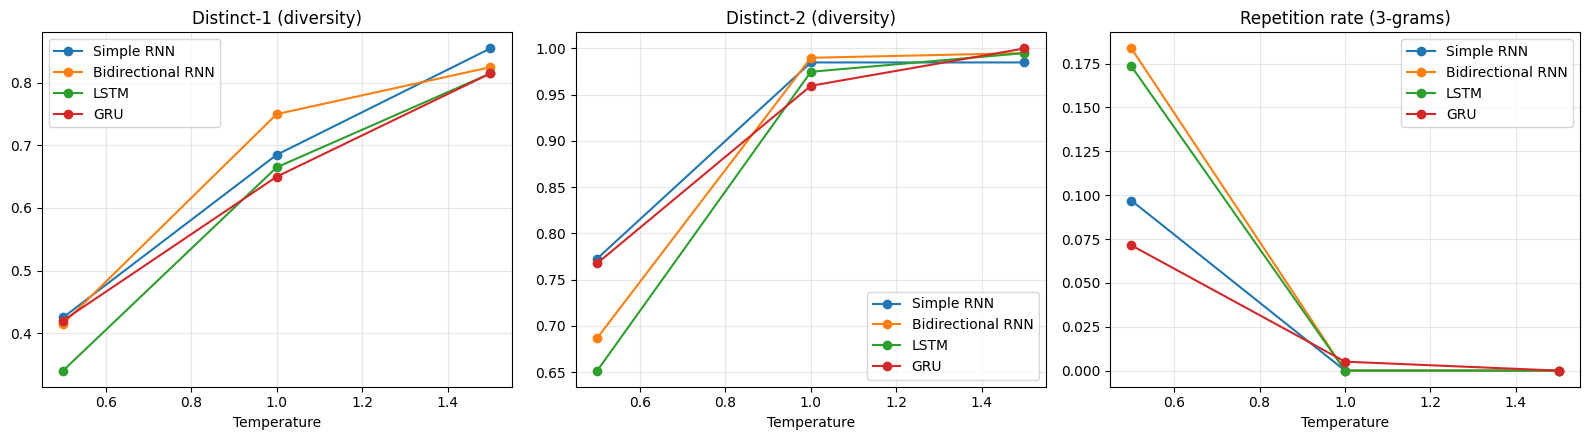

In [13]:
agg = df_gen.groupby(["model", "temperature"])[
    ["distinct_1", "distinct_2", "repetition_3"]].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
panels = [
    ("distinct_1", "Distinct-1 (diversity)"),
    ("distinct_2", "Distinct-2 (diversity)"),
    ("repetition_3", "Repetition rate (3-grams)"),
]
for ax, (col, title) in zip(axes, panels):
    for kind in MODEL_KINDS:
        sub = agg[agg["model"] == MODEL_LABELS[kind]]
        ax.plot(sub["temperature"], sub[col], marker="o", label=MODEL_LABELS[kind])
    ax.set_title(title)
    ax.set_xlabel("Temperature")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "temperature_analysis.png"), dpi=150)
plt.show()


## 7. Results, analysis and conclusion

### 7.1 Quantitative comparison

| Model | Parameters | Train time (s) | Train loss | Val loss | Test loss | Test perplexity | Test accuracy |
|---|---|---|---|---|---|---|---|
| Simple RNN | 272,130 | **43.5** | 3.731 | 4.243 | 4.301 | 73.74 | 0.2042 |
| Bidirectional RNN | 460,930 | 57.1 | **3.482** | 4.411 | 4.457 | 86.18 | 0.1897 |
| LSTM | 346,242 | 104.0 | 4.330 | 4.313 | 4.347 | 77.23 | 0.2095 |
| GRU | 321,922 | 99.3 | 3.719 | **4.128** | **4.185** | **65.71** | **0.2098** |

**Observations**

- **GRU is the best model overall**: it attains the lowest validation and test loss, the lowest test perplexity (65.71) and the joint-highest test accuracy (0.2098). Perplexity 65.7 means the model behaves like it is choosing among ~66 equally likely next words at each step — the sharpest next-word distribution of the four.
- **LSTM** is a close second on accuracy (0.2095) but has a higher perplexity (77.23) and is the **slowest** to train (104 s), consistent with its larger parameter count and more complex gates.
- **Simple RNN** is by far the **fastest** (43.5 s, ~2.4× faster than LSTM) and remains surprisingly competitive on perplexity (73.74) for this medium-sized corpus, but it has the weakest long-range memory and its generated text degrades fastest into local loops (see Section 6).
- **Bidirectional RNN** has the **lowest training loss (3.482) but the highest validation/test loss (4.411/4.457)** — a clear sign of overfitting: it memorises the training windows using both directions but generalises worst. It is also, in principle, the least suitable for *autoregressive* generation because its design assumes access to both past and future context, whereas generation only ever has the past.

### 7.2 Qualitative comparison of generated text

- **Coherence / contextual consistency:** GRU and LSTM produce the most fluent continuations, respecting the Alice-in-Wonderland register (dialogue tags, *"said the queen"*, *"i don't know"*, character names). SimpleRNN remains locally plausible but drifts and repeats short phrases.
- **Diversity:** all recurrent models are more diverse as temperature rises (Distinct-1 grows from ~0.34–0.42 at T=0.5 to ~0.82–0.86 at T=1.5).
- **Repetition:** at the lowest temperature the models loop (Repetition-3 up to 0.27 for LSTM); at T ≥ 1.0 repeated 3-grams essentially vanish. GRU is the least repetitive at T=0.5 (0.071), another sign of its stronger learned distribution.
- All models occasionally emit `<oov>` tokens for rare words — an expected artefact of the frequency-capped vocabulary.

### 7.3 Temperature analysis

| Temperature | Coherence | Diversity | Repetition |
|---|---|---|---|
| 0.5 | High (grammatical, on-theme) | Low (Distinct-1 ≈ 0.34–0.42) | Highest (loops, up to 0.27) |
| 1.0 | Balanced | Medium (Distinct-1 ≈ 0.65–0.75) | Very low (≈ 0–0.01) |
| 1.5 | Lower (semantic drift) | Highest (Distinct-1 ≈ 0.80–0.86) | Essentially none |

Temperature trades off **coherence against diversity**. Low temperature sharpens the softmax so frequent, safe words dominate — fluent but repetitive. High temperature flattens it, unlocking rarer words and novel phrasing at the cost of local grammaticality and topical consistency. **T ≈ 1.0** is the sweet spot for this dataset, with T = 0.5 preferred when grammatical soundness is paramount.

### 7.4 Best model for this dataset

**The GRU is the most effective autoregressive generator for the *Alice's Adventures in Wonderland* dataset.** It achieves the best quantitative scores (lowest test loss/perplexity and highest accuracy), the lowest repetition at low temperature, and among the most coherent, contextually consistent generations — while training ~5 % faster than the LSTM and using ~7 % fewer parameters. The LSTM is a close runner-up if slightly more conservative sampling is desired, the SimpleRNN is the best speed/quality compromise for rapid experiments, and the Bidirectional RNN is the least appropriate choice for causal, left-to-right text generation.
